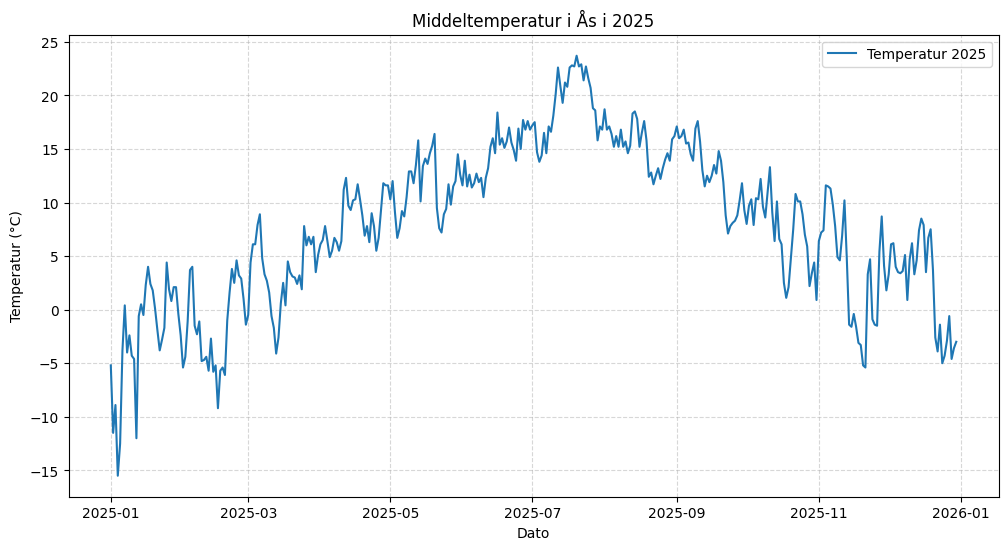

Gjennomsnitt: 7.9 °C
Median: 8.4 °C
Laveste temperatur: -15.5 °C
Høyeste temperatur: 23.7 °C


In [16]:

#Task 1

import matplotlib.pyplot as plt
import pandas as pd
import requests

# Hent klient-ID fra fil (fra forelesningsmetoden)
client_id = open("frost_credentials.txt").read().strip()

# Hent temperaturdata fra Frost API
url = "https://frost.met.no/observations/v0.jsonld"
parametre = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

svar = requests.get(url, params=parametre, auth=(client_id, ""))
assert svar.status_code == 200  # Sjekk fra forelesning
data = svar.json()["data"]

# Trekk ut data ved hjelp av listekomprehension
datoer = []
temperaturer = []
for dag in data:
  datoer.append(dag["referenceTime"])
  temperaturer.append(dag["observations"][0]["value"])

# Lag DataFrame (med Dato som kolonne og T_avg)
df = pd.DataFrame({"Dato": pd.to_datetime(datoer), "T_avg": temperaturer})

# Tegn graf for Task 1
plt.figure(figsize=(12, 6))
plt.plot(df["Dato"], df["T_avg"], color="tab:blue", label="Temperatur 2025")
plt.title("Middeltemperatur i Ås i 2025")
plt.xlabel("Dato")
plt.ylabel("Temperatur (°C)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

# Skriv ut statistikk
print("Gjennomsnitt:", round(df["T_avg"].mean(), 2), "°C")
print("Median:", round(df["T_avg"].median(), 2), "°C")
print("Laveste temperatur:", df["T_avg"].min(), "°C")
print("Høyeste temperatur:", df["T_avg"].max(), "°C")

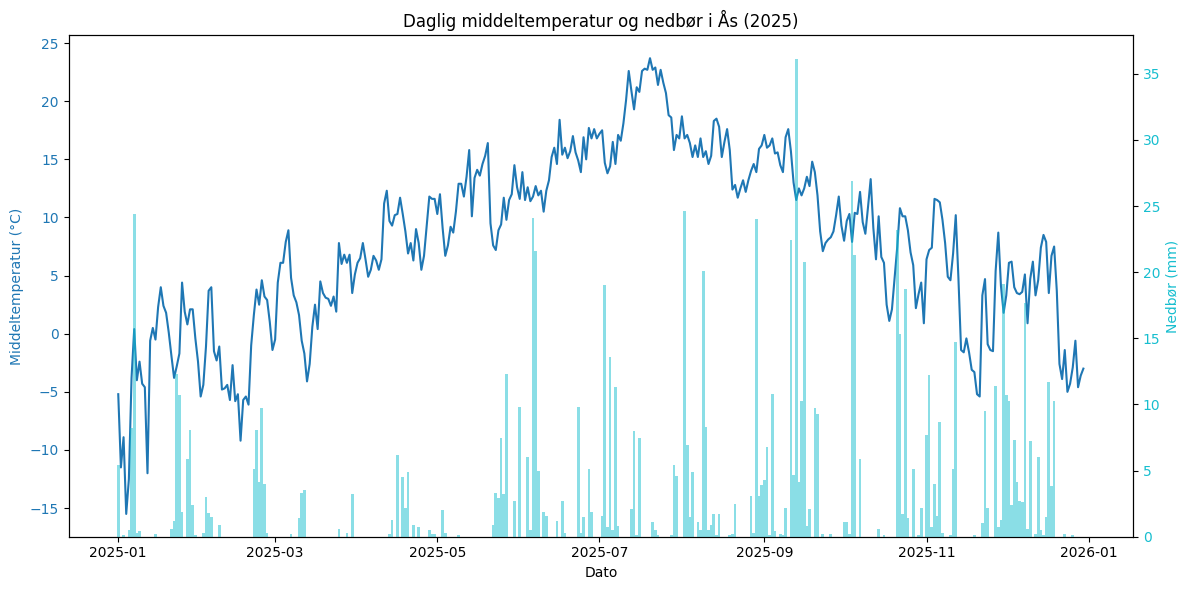

In [17]:
#Task 2

# Hent nedbørsdata for 2025
endpoint_precip = "https://frost.met.no/observations/v0.jsonld"
parameters_precip = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

response_precip = requests.get(
    endpoint_precip, parameters_precip, auth=(client_id, "")
)
assert response_precip.status_code == 200
payload_precip = response_precip.json()

precip_data = [
    {
        "Dato": pd.to_datetime(entry["referenceTime"]),
        "Precipitation": entry["observations"][0]["value"],
    }
    for entry in payload_precip["data"]
]
precip_df = pd.DataFrame.from_records(precip_data)

# Kombinert plott (Temperatur + Nedbør)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Venstre akse: Temperatur
color = "tab:blue"
ax1.set_xlabel("Dato")
ax1.set_ylabel("Middeltemperatur (°C)", color=color)
ax1.plot(df["Dato"], df["T_avg"], color=color, label="Temperatur")
ax1.tick_params(axis="y", labelcolor=color)

# Høyre akse: Nedbør (stolper)
ax2 = ax1.twinx()
color = "tab:cyan"
ax2.set_ylabel("Nedbør (mm)", color=color)
ax2.bar(
    precip_df["Dato"],
    precip_df["Precipitation"],
    color=color,
    width=1.0,
    alpha=0.5,
    label="Nedbør",
)
ax2.tick_params(axis="y", labelcolor=color)
ax2.grid(False)

plt.title("Daglig middeltemperatur og nedbør i Ås (2025)")
plt.tight_layout()
plt.show()

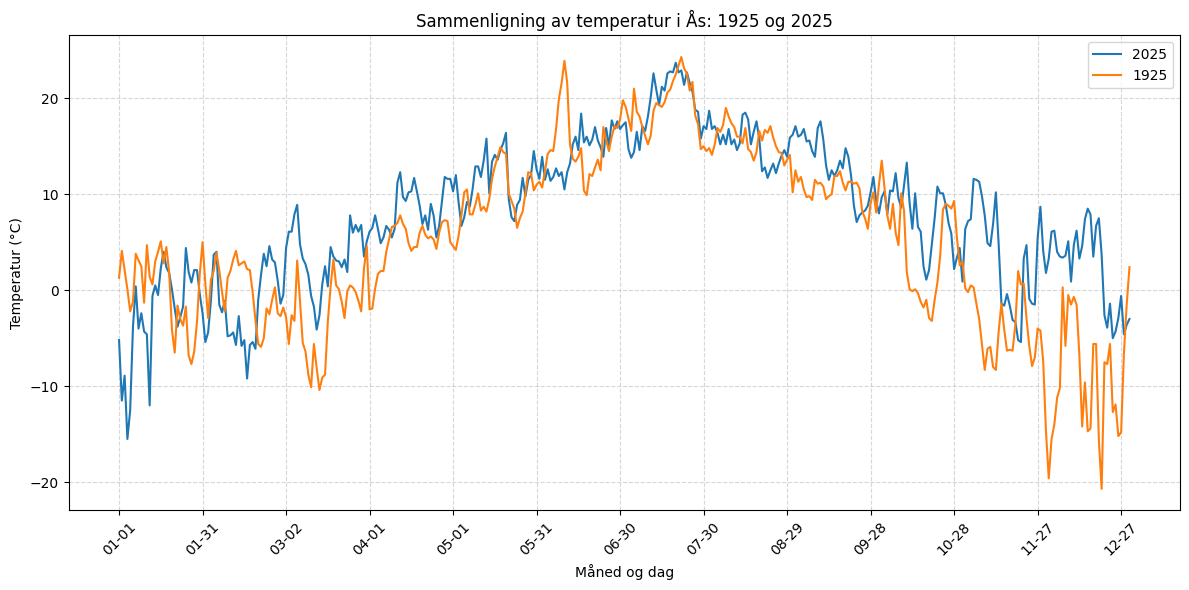

            TEMPERATUROPPSUMMERING: 2025 vs 1925            
Statistikk           |       2025 (°C) |       1925 (°C)
------------------------------------------------------------
Gjennomsnitt         |            7.90 |            5.31
Median               |            8.40 |            5.30
Minimum              |          -15.50 |          -20.70
Maksimum             |           23.70 |           24.30


In [18]:
#Task 3

# Hent temperaturdata for 1925
parameters_1925 = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1925-12-31",
}

response_1925 = requests.get(url, params=parameters_1925, auth=(client_id, ""))
assert response_1925.status_code == 205 or response_1925.status_code == 200
payload_1925 = response_1925.json()

temp_data_1925 = [
    {
        "Dato": pd.to_datetime(entry["referenceTime"]),
        "T_avg_1925": entry["observations"][0]["value"],
    }
    for entry in payload_1925["data"]
]
df_1925 = pd.DataFrame.from_records(temp_data_1925)

# Forbered sammenslåing via måned og dag
df["day_month"] = df["Dato"].dt.strftime("%m-%d")
df_1925["day_month"] = df_1925["Dato"].dt.strftime("%m-%d")

comparison_df = pd.merge(
    df[["day_month", "T_avg"]],
    df_1925[["day_month", "T_avg_1925"]],
    on="day_month",
    how="inner",
).sort_values("day_month")

# Plott begge årene
plt.figure(figsize=(12, 6))
plt.plot(
    range(len(comparison_df)),
    comparison_df["T_avg"],
    label="2025",
    color="tab:blue",
)
plt.plot(
    range(len(comparison_df)),
    comparison_df["T_avg_1925"],
    label="1925",
    color="tab:orange",
)

step = 30
plt.xticks(
    range(0, len(comparison_df), step),
    comparison_df["day_month"].iloc[::step],
    rotation=45,
)
plt.title("Sammenligning av temperatur i Ås: 1925 og 2025")
plt.xlabel("Måned og dag")
plt.ylabel("Temperatur (°C)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Oppsummeringstabell med print()
mean_2025, median_2025 = comparison_df["T_avg"].mean(), comparison_df["T_avg"].median()
min_2025, max_2025 = comparison_df["T_avg"].min(), comparison_df["T_avg"].max()

mean_1925, median_1925 = (
    comparison_df["T_avg_1925"].mean(),
    comparison_df["T_avg_1925"].median(),
)
min_1925, max_1925 = (
    comparison_df["T_avg_1925"].min(),
    comparison_df["T_avg_1925"].max(),
)

print("=" * 60)
print(f"{'TEMPERATUROPPSUMMERING: 2025 vs 1925':^60}")
print("=" * 60)
print(f"{'Statistikk':<20} | {'2025 (°C)':>15} | {'1925 (°C)':>15}")
print("-" * 60)
print(f"{'Gjennomsnitt':<20} | {mean_2025:>15.2f} | {mean_1925:>15.2f}")
print(f"{'Median':<20} | {median_2025:>15.2f} | {median_1925:>15.2f}")
print(f"{'Minimum':<20} | {min_2025:>15.2f} | {min_1925:>15.2f}")
print(f"{'Maksimum':<20} | {max_2025:>15.2f} | {max_1925:>15.2f}")
print("=" * 60)

In [19]:
import yaml


def count_heatwaves(station_id, year, client_id):
  endpoint = "https://frost.met.no/observations/v0.jsonld"
  parameters = {
      "sources": station_id,
      "elements": "max(air_temperature P1D)",
      "referencetime": f"{year}-01-01/{year}-12-31",
  }

  response = requests.get(endpoint, parameters, auth=(client_id, ""))
  assert response.status_code == 200
  payload = response.json()

  data = [
      {
          "Dato": pd.to_datetime(entry["referenceTime"]),
          "T_max": entry["observations"][0]["value"],
      }
      for entry in payload["data"]
  ]
  df_max = pd.DataFrame.from_records(data)

  heatwave_count = 0
  consecutive_days = 0

  for temp in df_max["T_max"]:
    if temp >= 27:
      consecutive_days += 1
    else:
      if consecutive_days >= 5:
        heatwave_count += 1
      consecutive_days = 0

  if consecutive_days >= 5:
    heatwave_count += 1

  summary = {"station": station_id, "year": year, "heatwaves": heatwave_count}

  filename = f"heatwave_summary_{station_id}_{year}.yml"
  with open(filename, "w") as f:
    yaml.dump(summary, f)

  print(f"Antall hetebølger for {station_id} i {year}: {heatwave_count}")
  return heatwave_count


# Kjør funksjonen for Ås i 2025
count_heatwaves("SN17850", 2025, client_id)

Antall hetebølger for SN17850 i 2025: 1


1

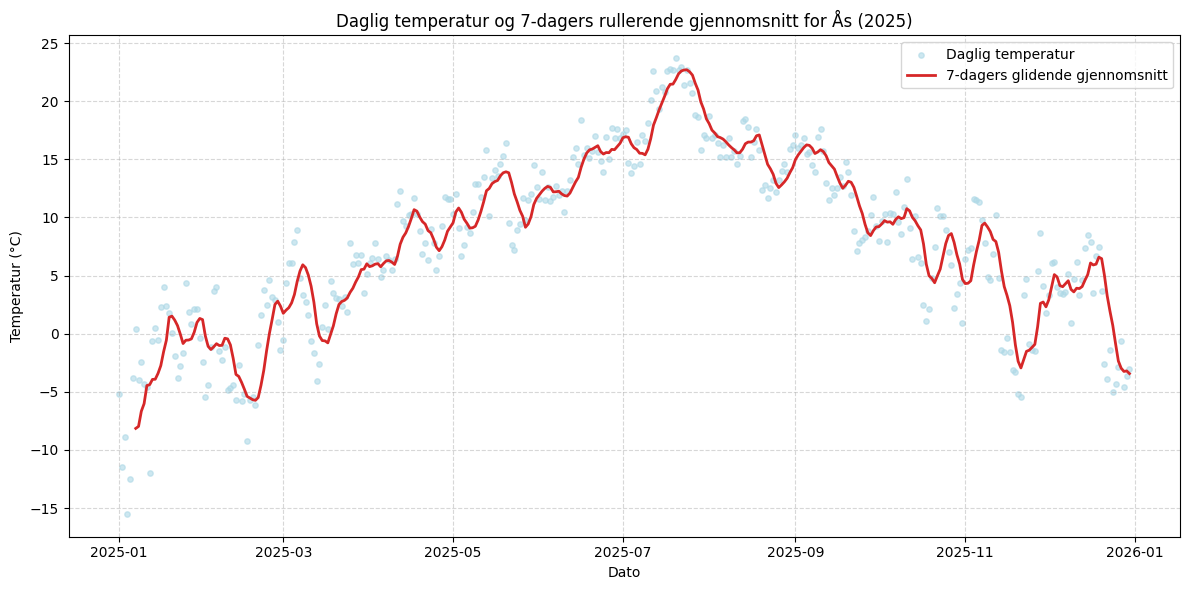

In [20]:
def calculate_moving_average(dataframe, window_size=7):
  return dataframe["T_avg"].rolling(window=window_size).mean()


# Bruk funksjonen på 2025-datatabellen fra Task 1
df["T_mav"] = calculate_moving_average(df, window_size=7)

# Plott daglig temperatur som punkter og rullerende snitt som linje
plt.figure(figsize=(12, 6))
plt.scatter(
    df["Dato"],
    df["T_avg"],
    color="lightblue",
    s=15,
    label="Daglig temperatur",
    alpha=0.6,
)
plt.plot(
    df["Dato"],
    df["T_mav"],
    color="tab:red",
    linewidth=2,
    label="7-dagers glidende gjennomsnitt",
)

plt.title("Daglig temperatur og 7-dagers rullerende gjennomsnitt for Ås (2025)")
plt.xlabel("Dato")
plt.ylabel("Temperatur (°C)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()